# Global Power Plant Database Analysis
**Author:** Husnain Zahoor  
**Date:** Nov 18, 2026  
**Dataset:** Global Power Plant Database v1.2.0 (released 2019-06-12), World Resources Institute and data contributors.

**Version check:** I also checked the newer WRI v1.3.0 (June 2021). Saudi Arabia has 90 plants there but no reported generation for 2013 to 2019, so it would not remove the Saudi generation gap.

**Decision:** I kept v1.2.0 because it meets all Must-Have requirements and switching would not fix the limitation. The newer version is noted as a limitation in the write-up.

**Source URL:** https://datasets.wri.org/dataset/globalpowerplantdatabase

**Downloaded from:** Kaggle copy of the WRI release, https://www.kaggle.com/datasets/mathurinache/global-power-plant-database
**Licence:** CC BY 4.0. Copyright 2018-2019 World Resources Institute and Data Contributors

**Credit:** Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, World Resources Institute. 2019. Global Power Plant Database.

---

### Context & Pipeline Position
This is notebook 4 of 5 (Regression). It answers **Sub-question 3**: How well do capacity_mw, commissioning_year, and primary_fuel predict generation_gwh_2017 (R²), and
which input carries the most weight (standardized coefficient / feature importance)?

**Inputs:** model_ready_plants.pkl (Notebook 1): 8,778 plants, 28 columns.

**Outputs:** Regression results, model evaluation metrics, actual vs predicted generation comparison, and a comparison of capacity-only, fuel-only, and combined models.

**Scope:** Build a capacity-only baseline model first, then investigate whether fuel type improves generation predictions. The analysis uses historical 2017 generation data.

# Environment Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
DATA_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Dataset/'
OUTPUT_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Output/'

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# FORCE PANDAS TO SHOW ALL COLUMNS HORIZONTALLY (NO WRAPPING)
pd.set_option('display.max_columns', None)  # Show every column
pd.set_option('display.width', 1000)        # Give the text engine plenty of horizontal width

# Loading the data set

In [5]:
df_final = pd.read_pickle(OUTPUT_PATH + 'model_ready_plants.pkl')
print(f'Loaded Successfully: {df_final.shape[0]} rows, {df_final.shape[1]} columns')

Loaded Successfully: 8778 rows, 28 columns


In [6]:
df_final.head(5)

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,other_fuel3,commissioning_year,owner,source,url,geolocation_source,wepp_id,year_of_capacity_data,generation_gwh_2013,generation_gwh_2014,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017,estimated_generation_gwh,commissioning_year_raw,flag_over_max,flag_negative_gen_2017,capacity_factor
12091,IND,India,AGARTALA GT,IND0000001,135.0,23.8712,91.3602,Gas,NaN,NaN,NaN,2004,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1024373,2018,631.777928,617.789264,843.7470,886.004428,663.774500,NaN,2004.0,False,False,0.561284
12092,IND,India,AKALTARA TPP,IND0000002,1800.0,21.9603,82.4091,Coal,Oil,NaN,NaN,2015,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1069957,2018,1668.290000,3035.550000,5916.3700,6243.000000,5385.579736,NaN,2015.0,False,False,0.341551
12093,IND,India,AKRIMOTA LIG,IND0000003,250.0,23.7689,68.6447,Coal,Oil,NaN,NaN,2005,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1017933,2018,821.798000,1153.421000,1208.8520,1175.765000,1147.913000,NaN,2005.0,False,False,0.524161
12094,IND,India,ALIYAR,IND0000004,60.0,10.4547,77.0078,Hydro,NaN,NaN,NaN,1970,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1030923,2018,147.568450,157.558250,152.1952,61.421350,89.629600,NaN,1970.0,False,False,0.170528
12095,IND,India,ALLAIN DUHANGAN,IND0000005,192.0,32.2258,77.2070,Hydro,NaN,NaN,NaN,2010,NaN,Central Electricity Authority,http://www.cea.nic.in/,WRI,1026499,2018,696.738800,674.391100,721.3352,675.724400,679.594950,NaN,2010.0,False,False,0.404059


## Exercise 1
State and visualize your hypothesis. Choose one predictor (X) and one outcome (y) from your own dataset. Build a scatterplot of X against y. In a markdown cell, state your hypothesis. Use a direction, for example: "more X means more y." Name the research question this hypothesis connects to. Submit the scatterplot and your hypothesis.

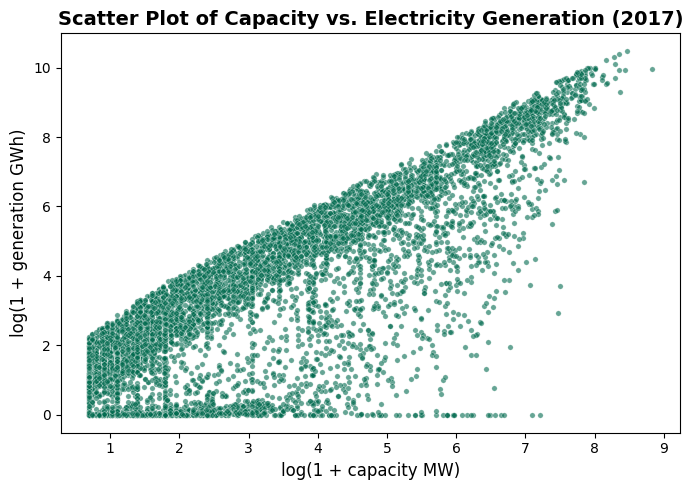

In [7]:
# Log transform the two skewed columns (new columns, originals kept)
df_final['log_capacity'] = np.log1p(df_final['capacity_mw'])
df_final['log_generation_2017'] = np.log1p(df_final['generation_gwh_2017'])

# Create scatter plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_final, x="log_capacity", y="log_generation_2017",s=15, alpha=0.6, color="#006A4E")

# Set labels and title
plt.xlabel("log(1 + capacity MW)", fontsize=12)
plt.ylabel("log(1 + generation GWh)", fontsize=12)
plt.title("Scatter Plot of Capacity vs. Electricity Generation (2017)", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

**It answers subquestion 3:** How well do capacity_mw, commissioning_year, and primary_fuel predict generation_gwh_2017 (R-squared),
and which input carries the most weight (standardized coefficient / feature importance)? But this model uses one input which is log_capacity and rest of the input used below notebook in separate section. The plot uses log values why (a few giant plants squash everything else on a normal scale).

The scatterplot shows a positive relationship between installed capacity and electricity generation. My hypothesis is that plants with higher installed capacity generally generate more electricity.

## Exercise 2
Prepare and split your data. Reshape your X and y variables into NumPy arrays. Split your data into a training set (70 percent) and a test set (30 percent). Use train_test_split() with random_state=42. In a markdown cell, explain why the model is tested on data it has not seen before. Submit your split code and your explanation.

In [8]:
# Log transform the two skewed columns (new columns, originals kept)
df_final['log_capacity'] = np.log1p(df_final['capacity_mw'])
df_final['log_generation_2017'] = np.log1p(df_final['generation_gwh_2017'])

X = np.array(df_final["log_capacity"]).reshape(-1, 1)
y = np.array(df_final["log_generation_2017"]).reshape(-1, 1)

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print('Train_Size:',X_train.shape, 'Test_Size:',X_test.shape)

Train_Size: (6144, 1) Test_Size: (2634, 1)


I trained the model using 70% of the 8,778 plants (6,144 plants) and tested it using the remaining 30% (2,634 plants) the model never saw.

#### ***Testing on unseen data is essential for the following reasons:***

A regression model is tested on data it has not seen before (unseen or test data) to measure its true generalization ability how well it predicts outcomes in the real world rather than just memorizing the examples it was trained on.

**• Preventing Overfitting:** If a model is evaluated only on the data it was trained on, it can achieve high accuracy by simply "memorizing" specific data points and noise rather than learning the actual underlying patterns.

**• Measuring Out-of-Sample Accuracy:** The primary goal of a predictive model is to perform well on future, unknown data. Evaluating out-of-sample accuracy gives a realistic estimate of how the model will behave in production.

**• Detecting High Test Error:** Comparing training error to test error helps diagnose problems. A model with very low training error but high test error is a clear warning sign of overfitting.

## Exercise 3

Run your regression and visualize the fit. Create a LinearRegression object. Fit it to your training data. Generate predictions on your test set. Plot the regression line against your test set's actual values. Submit your code and your plot.

In [10]:
from sklearn.linear_model import LinearRegression

regression = LinearRegression()
regression.fit(X_train, y_train)           #Fit the model on the training data
y_predicted = regression.predict(X_test)   #Generate predictions on the test set

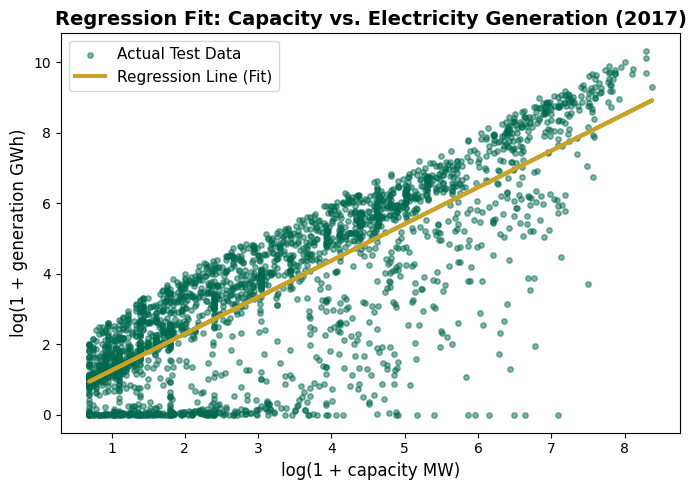

In [11]:
# Initialize figure
plt.figure(figsize=(7, 5))

# Plot the actual test data points
plt.scatter(X_test, y_test, color="#006A4E",s=15, alpha=0.5, label="Actual Test Data")

# Plot the regression line
plt.plot(X_test, y_predicted, color="#C9A227", linewidth=2.9, label="Regression Line (Fit)")

# Labels and titles
plt.xlabel("log(1 + capacity MW)", fontsize=12)
plt.ylabel("log(1 + generation GWh)", fontsize=12)
plt.title("Regression Fit: Capacity vs. Electricity Generation (2017)", fontsize=14, fontweight="bold")
plt.legend(fontsize=11)

# Show plot
plt.tight_layout()
plt.show()

The line rises with the points, and a row of points at the very bottom (zero-output plants) sits far below it. That spread is why R² is not higher.

## Exercise 4
Evaluate and interpret. Report your model's slope, RMSE, and R² on the test set. Build a table that compares actual y values to predicted y values, for a sample of test rows. In a markdown cell, do three things. First, state whether your model supports or contradicts your hypothesis. Second, name at least one limitation, for example sample size, non-linearity, or possible bias. Third, look at your Lesson 2 correlation heatmap. Name one other variable that might predict your outcome better or worse than the one you chose, and explain why. You do not need to rerun the model for this step. Record your findings in Capstone_Findings.docx. Submit your metrics, your comparison table, your written interpretation, and the updated findings document.

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

slope = regression.coef_[0][0]
mse = mean_squared_error(y_test, y_predicted)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_predicted)

print("Slope:", round(slope, 4))
print("RMSE:", round(rmse, 2))
print("R2 (test):", round(r2, 4))
print("R2 (train):", round(r2_score(y_train, regression.predict(X_train)), 4))

Slope: 1.0396
RMSE: 1.38
R2 (test): 0.693
R2 (train): 0.691


### Interpretation of Results

The capacity-only regression model produced the following results:

- **Slope: 1.0396** — A 1% increase in installed capacity is associated with approximately a 1.04% increase in predicted generation. Both variables are log-transformed.
- **RMSE: 1.38** — This measures the size of the model's prediction errors in log units, not GWh.
- **Test R²: 0.693** — The model explains approximately 69.3% of the variation in log-transformed electricity generation in the test data. This does not mean the model is 69.3% accurate.
- **Train R²: 0.691** — The training and testing results are very close, suggesting no obvious sign of overfitting.

**Conclusion:** Installed capacity is a useful predictor of electricity generation, but it does not explain all the variation. The slope is positive and R² is 0.69, so the hypothesis is supported. From the correlation heatmap from Lesson#2 Commissioning_Year is the variable that predict the outcome worse because plants mainly differ by size not age.

**Limitations:**

*   The dataset is dominated by US power plants (approximately 95%) and contains no Saudi plants. Therefore, these results should not be assumed to represent the performance of Saudi power plants.

*   317 of the 8,778 modelling plants (3.6%) report exactly 0 GWh in 2017. They are mostly small (median 4.3 MW) and mostly US (288) or Indian (29), led by oil (102), gas (65) and solar (57). I kept them because I cannot tell idle plants from missing reports. Refitting the capacity-only model without them raises test R² from 0.693 to 0.727, but the slope barely changes (1.040 vs 1.042), so the main finding does not depend on them. Why these plants report zero was not investigated.



In [13]:
comparison = pd.DataFrame({
    "Actual_log": y_test.flatten(),
    "Predicted_log": y_predicted.flatten()
})

# Convert log values back to original GWh
comparison["Actual_GWh"] = np.expm1(comparison["Actual_log"])
comparison["Predicted_GWh"] = np.expm1(comparison["Predicted_log"])

# Calculate prediction errors in GWh
comparison["Error_GWh"] = (
    comparison["Actual_GWh"] - comparison["Predicted_GWh"]
)

comparison["Absolute_Error_GWh"] = comparison["Error_GWh"].abs()

# Keep your original log-scale difference for reference
comparison["Difference_log"] = (
    comparison["Actual_log"] - comparison["Predicted_log"]
)

comparison.sample(8, random_state=42).round(2)


,Actual_log,Predicted_log,Actual_GWh,Predicted_GWh,Error_GWh,Absolute_Error_GWh,Difference_log
1094,6.07,4.68,432.56,106.42,326.14,326.14,1.40
1124,2.90,2.61,17.22,12.56,4.66,4.66,0.30
602,0.00,2.24,0.00,8.36,-8.36,8.36,-2.24
693,4.51,4.83,89.48,124.48,-34.99,34.99,-0.33
408,0.06,2.09,0.06,7.11,-7.05,7.05,-2.04
1146,0.00,7.59,0.00,1968.14,-1968.14,1968.14,-7.59
1222,2.55,2.24,11.78,8.36,3.42,3.42,0.31
927,2.81,1.49,15.59,3.42,12.17,12.17,1.32


## Extension: adding fuel type (beyond Lesson 5)

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Group fuels with fewer than 50 plants into "Other" (keeps all 8,778 rows)
fuel_counts = df_final['primary_fuel'].value_counts()
small = fuel_counts[fuel_counts < 50].index
df_final['fuel_grouped'] = np.where(df_final['primary_fuel'].isin(small), 'Other', df_final['primary_fuel'])

# Turn fuel text into 0/1 columns (one per fuel, one fuel left out as the baseline)
fuel_dummies = pd.get_dummies(df_final['fuel_grouped'], drop_first=True, dtype=float)

y = df_final['log_generation_2017']
year = df_final[['commissioning_year']].astype(float)
cap = df_final[['log_capacity']]

def run(X, label):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    return {"Model": label,
            "R2 test": r2_score(y_te, pred),
            "R2 train": r2_score(y_tr, m.predict(X_tr)),
            "RMSE (log)": mean_squared_error(y_te, pred) ** 0.5}

results = pd.DataFrame([
    run(cap, "Capacity only"),
    run(fuel_dummies, "Fuel only"),
    run(year, "Build year only"),
    run(pd.concat([cap, fuel_dummies], axis=1), "Capacity + fuel"),
    run(pd.concat([cap, fuel_dummies, year], axis=1), "Capacity + fuel + year"),
]).round(3)
results

,Model,R2 test,R2 train,RMSE (log)
0,Capacity only,0.693,0.691,1.376
1,Fuel only,0.423,0.445,1.886
2,Build year only,0.005,0.014,2.476
3,Capacity + fuel,0.791,0.798,1.134
4,Capacity + fuel + year,0.793,0.799,1.129


In [15]:
df_final.groupby('fuel_grouped')['log_capacity'].median().round(2)

,log_capacity
fuel_grouped,
Biomass,2.20
Coal,6.49
Gas,4.73
Geothermal,3.43
Hydro,2.40
Nuclear,7.35
Oil,2.05
Other,2.56
Solar,1.50


### Final Findings

I investigated 3 main predictors of electricity generation:

- Installed capacity (MW)
- Primary fuel type
- Commissioning year

I first built a baseline regression model using installed capacity alone. Then I compared it with a model using fuel type alone and a combined model using both capacity and fuel type.

**Results:**

- Capacity alone explains 69.3% of the variation in log-transformed generation.
- Fuel type alone explains 42.3%.
- Combining capacity and fuel type increases the test R² to 79.1%.

**Conclusion:**

Installed capacity is a strong predictor of electricity generation. Fuel type also provides useful predictive information. Using both together gives better results than using either one alone. All of this describes US plants, not Saudi plants.